# 03 · Potential evapotranspiration (Hargreaves)

$$PET = 0.0023 \cdot 0.408\,R_a \cdot (T + 17.8) \cdot \sqrt{T_{max} - T_{min}} \quad [mm/day]$$

multiplied by the number of days in the month. $R_a$ (MJ m⁻² day⁻¹) is computed on the 15th of each
month with FAO-56 eq. 21 (`extraterrestrial_radiation`, given). $0.408$ converts MJ m⁻² day⁻¹ to mm/day.

In [1]:
%load_ext autoreload
%autoreload 2                  # reload edited src/epss modules automatically
import sys, json
from pathlib import Path
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path("../data")
PROC = DATA / "processed"
PROC.mkdir(exist_ok=True)
case = json.loads((DATA / "case.json").read_text())
case

{'catchment_area_km2': 55.33,
 'latitude_deg': 38.237,
 'longitude_deg': -7.687,
 'smax_mm': 100,
 'hmax_m': 5.0,
 'hmin_m': 1.0,
 'area_fixed_km2': 0.0685,
 'irrigation_months': [6, 7, 8, 9],
 'demand_hm3_per_month': 0.02,
 'eflow_fraction': 0.1,
 'target_reliability': 0.9}

In [2]:
from epss.pet import extraterrestrial_radiation, pet_monthly

clim = pd.read_csv(PROC / "climate.csv", index_col=0, parse_dates=True)
lat = case["latitude_deg"]
doy15 = pd.date_range("2001-01-15", periods=12, freq="MS") + pd.Timedelta(days=14)
ra = extraterrestrial_radiation(lat, doy15.day_of_year)

pet = pet_monthly(clim.t_c, clim.tmax_c, clim.tmin_c, lat)
pet.to_csv(PROC / "pet.csv")
pet.describe().round(1)

count    480.0
mean     101.3
std       56.7
min       26.9
25%       43.5
50%       91.6
75%      156.3
max      219.5
Name: pet, dtype: float64

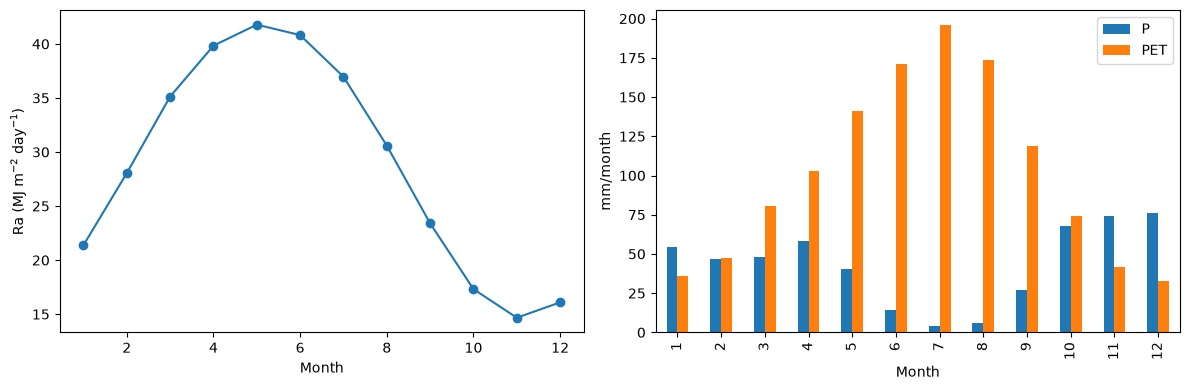

In [3]:
monthly = pd.DataFrame({"P": clim.p_mm, "PET": pet}).groupby(clim.index.month).mean()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 13), ra, "o-")
ax[0].set_xlabel("Month"); ax[0].set_ylabel("Ra (MJ m$^{-2}$ day$^{-1}$)")
monthly.plot.bar(ax=ax[1], color=["tab:blue", "tab:orange"])
ax[1].set_xlabel("Month"); ax[1].set_ylabel("mm/month")
plt.tight_layout()

In [4]:
# TODO: List the calendar months in which mean PET > mean P.
# In: monthly (DataFrame with columns P, PET by month)
# Out: dry_months (list of month numbers)
raise NotImplementedError('List the calendar months in which mean PET > mean P.')
print("Months with PET > P:", dry_months)
print(f"Annual PET {pet.groupby(pet.index.year).sum().mean():.0f} mm, annual P {clim.p_mm.groupby(clim.index.year).sum().mean():.0f} mm")

Months with PET > P: [2, 3, 4, 5, 6, 7, 8, 9, 10]
Annual PET 1216 mm, annual P 518 mm


**Answer.**

*Your answer here.*